## PCA

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = pd.read_csv('../pliki/wine.csv')
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


### wyznaczenie zmiennych wejściowych

In [7]:
X = wine.iloc[:,0:11]

### standaryzacja danych

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### metoda PCA dla dwóch składowych

In [9]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

### udział wyjaśnionej wariancji

In [10]:
pca.explained_variance_ratio_

array([0.28692345, 0.17075104])

### wykres dwóch pierwszych składowych

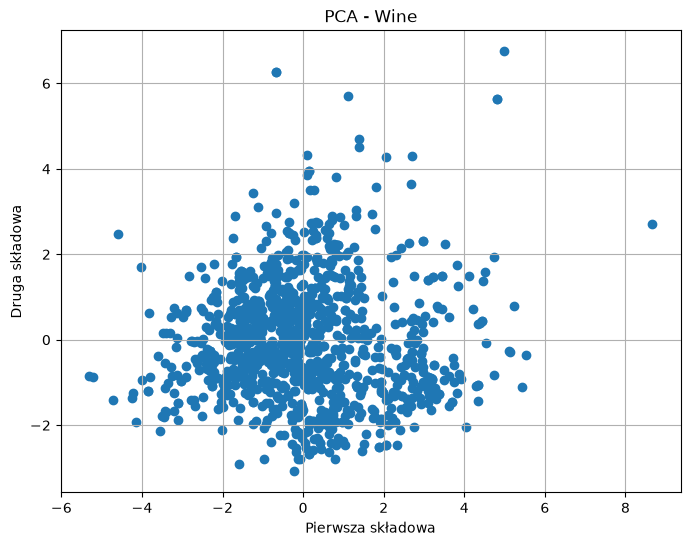

In [11]:
plt.figure(figsize=(8,6))
plt.scatter(
 X_pca[:,0],
 X_pca[:,1]
)
plt.xlabel("Pierwsza składowa")
plt.ylabel("Druga składowa")
plt.title("PCA - Wine")
plt.grid(True)
plt.show()

### macierz składowych głównych

In [14]:
import pandas as pd

components = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=["PC1", "PC2"]
)

components

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
PC1,0.485339,-0.227143,0.460075,0.174506,0.224870,-0.047852,0.015069,0.399684,-0.432844,0.237555,-0.118799
PC2,-0.102328,0.288786,-0.146508,0.252262,0.153133,0.517022,0.577393,0.217537,-0.006374,-0.062280,-0.381635
